# Self-Play Result Analysis (LBF)
Analyze self-play cooperator evaluations using `random_teammate_eval.json` and `scripted_policy_eval.json`.

Loaded 11 self-play LBF runs from /home/kang/zeroshot_coordination/scripts/self-play/results/lbf/self_play.


,experiment_root,run_tag,scripted_reward_mean,random_teammate_reward_mean,scripted_eval_path,random_eval_path
0,/home/kang/zeroshot_coordination/scripts/self-...,2026-02-26_21-16-24,0.678667,0.753238,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
1,/home/kang/zeroshot_coordination/scripts/self-...,2026-02-28_01-23-13,0.658667,0.477000,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
2,/home/kang/zeroshot_coordination/scripts/self-...,2026-02-28_05-07-37,0.658333,0.481667,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
3,/home/kang/zeroshot_coordination/scripts/self-...,2026-02-28_07-17-57,0.610238,0.535333,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
4,/home/kang/zeroshot_coordination/scripts/self-...,2026-02-28_09-36-07,0.570333,0.615333,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
5,/home/kang/zeroshot_coordination/scripts/self-...,2026-02-28_11-49-48,0.596571,0.585667,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
6,/home/kang/zeroshot_coordination/scripts/self-...,verbalized_sampling_run_1_2026-02-28_21-46-42,0.681905,0.547333,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
7,/home/kang/zeroshot_coordination/scripts/self-...,verbalized_sampling_run_2_2026-03-01_00-00-14,0.569333,0.685000,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
8,/home/kang/zeroshot_coordination/scripts/self-...,verbalized_sampling_run_3_2026-03-01_02-21-20,0.599000,0.617143,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...
9,/home/kang/zeroshot_coordination/scripts/self-...,verbalized_sampling_run_4_2026-03-01_04-39-39,0.714667,0.525667,/home/kang/zeroshot_coordination/scripts/self-...,/home/kang/zeroshot_coordination/scripts/self-...


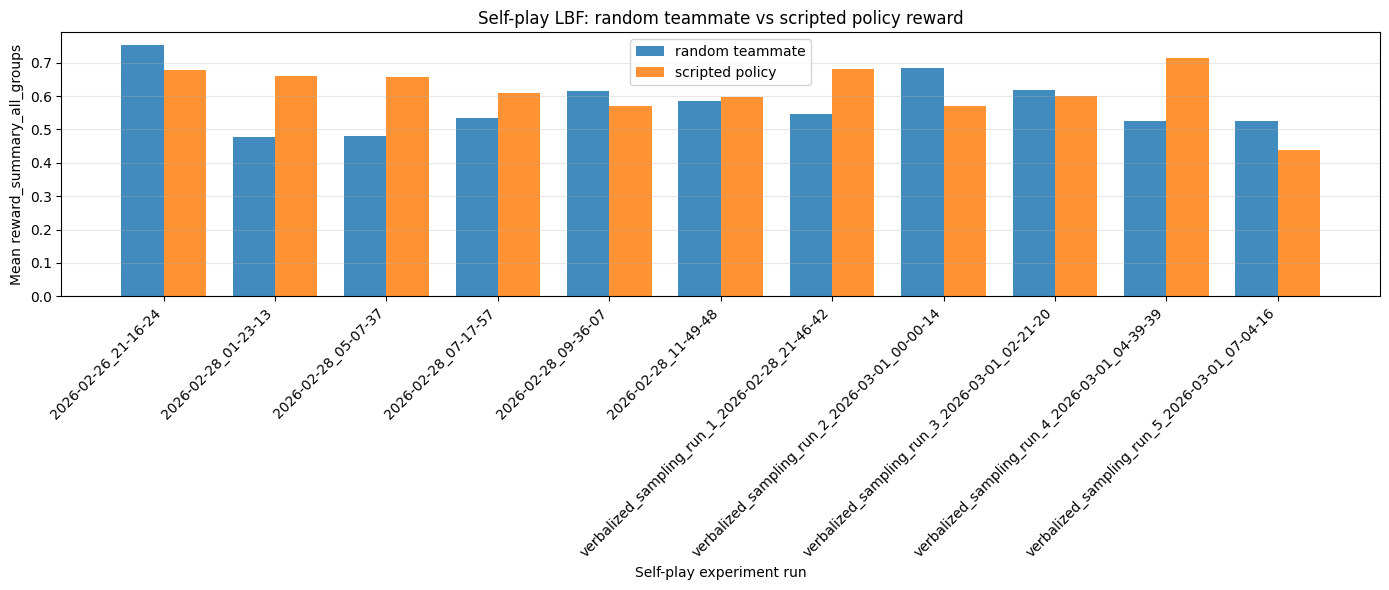

In [5]:
from __future__ import annotations

import json
from pathlib import Path

import pandas as pd

try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)


def _resolve_results_root() -> Path:
    candidates = [
        Path('results/lbf/self_play'),
        Path('scripts/self-play/results/lbf/self_play'),
        Path.cwd() / 'results/lbf/self_play',
        Path.cwd() / 'scripts/self-play/results/lbf/self_play',
    ]
    for c in candidates:
        if c.exists():
            return c.resolve()
    return Path('results/lbf/self_play').resolve()


RESULTS_ROOT = _resolve_results_root()


def _safe_json_load(path: Path):
    with path.open('r', encoding='utf-8') as f:
        return json.load(f)


def _extract_reward_mean(eval_json_path: Path):
    try:
        payload = _safe_json_load(eval_json_path)
    except Exception:
        return None

    return payload.get('reward_summary_all_groups', {}).get('mean')


def load_self_play_lbf_results(results_root: Path = RESULTS_ROOT) -> pd.DataFrame:
    rows = []

    if not results_root.exists():
        return pd.DataFrame(rows)

    experiment_dirs = sorted([d for d in results_root.iterdir() if d.is_dir()])
    for exp_dir in experiment_dirs:
        cooperator_root = exp_dir / 'cooperator'
        if not cooperator_root.is_dir():
            continue

        # Support both layouts:
        #   cooperator/<run_tag>/evaluation/*.json
        #   cooperator/<model_id>/evaluation/*.json
        eval_dirs = sorted([d for d in cooperator_root.glob('*/evaluation') if d.is_dir()])
        if not eval_dirs:
            continue

        eval_dir = eval_dirs[-1]
        scripted_path = eval_dir / 'scripted_policy_eval.json'
        random_path = eval_dir / 'random_teammate_eval.json'

        if not (scripted_path.exists() and random_path.exists()):
            continue

        scripted_mean = _extract_reward_mean(scripted_path)
        random_mean = _extract_reward_mean(random_path)
        if scripted_mean is None or random_mean is None:
            continue

        rows.append(
            {
                'experiment_root': str(exp_dir.resolve()),
                'run_tag': exp_dir.name,
                'scripted_reward_mean': float(scripted_mean),
                'random_teammate_reward_mean': float(random_mean),
                'scripted_eval_path': str(scripted_path.resolve()),
                'random_eval_path': str(random_path.resolve()),
            }
        )

    return pd.DataFrame(rows).sort_values('run_tag').reset_index(drop=True)


self_play_eval_df = load_self_play_lbf_results()
print(f'Loaded {len(self_play_eval_df)} self-play LBF runs from {RESULTS_ROOT}.')
display(self_play_eval_df)


if self_play_eval_df.empty:
    print('No self-play LBF runs found with both scripted/random eval files.')
else:
    import numpy as np
    import matplotlib.pyplot as plt

    x = np.arange(len(self_play_eval_df))
    width = 0.38

    fig_w = max(14, 1.2 * len(self_play_eval_df))
    plt.figure(figsize=(fig_w, 6))

    plt.bar(
        x - width / 2,
        self_play_eval_df['random_teammate_reward_mean'],
        width=width,
        label='random teammate',
        alpha=0.85,
    )
    plt.bar(
        x + width / 2,
        self_play_eval_df['scripted_reward_mean'],
        width=width,
        label='scripted policy',
        alpha=0.85,
    )

    plt.xticks(x, self_play_eval_df['run_tag'], rotation=45, ha='right')
    plt.xlabel('Self-play experiment run')
    plt.ylabel('Mean reward_summary_all_groups')
    plt.title('Self-play LBF: random teammate vs scripted policy reward')
    plt.grid(True, axis='y', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


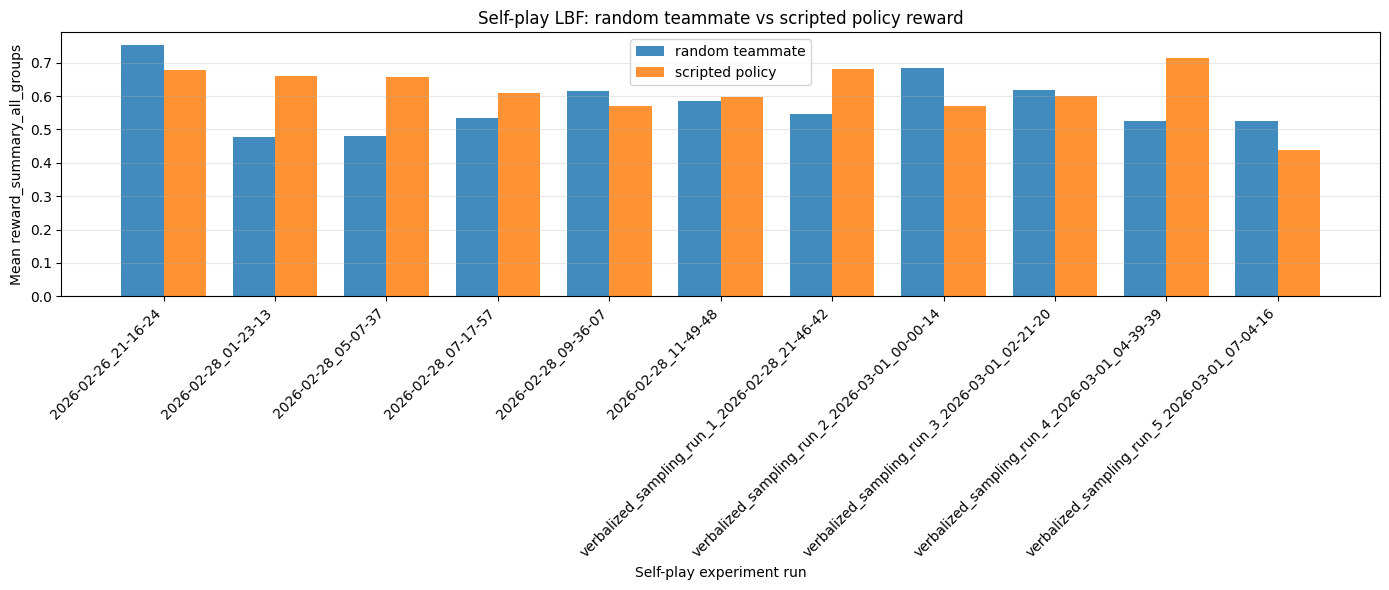

In [6]:
import numpy as np
import matplotlib.pyplot as plt

if self_play_eval_df.empty:
    print('No self-play LBF runs found with both scripted/random eval files.')
else:
    x = np.arange(len(self_play_eval_df))
    width = 0.38

    fig_w = max(14, 1.2 * len(self_play_eval_df))
    plt.figure(figsize=(fig_w, 6))

    plt.bar(
        x - width / 2,
        self_play_eval_df['random_teammate_reward_mean'],
        width=width,
        label='random teammate',
        alpha=0.85,
    )
    plt.bar(
        x + width / 2,
        self_play_eval_df['scripted_reward_mean'],
        width=width,
        label='scripted policy',
        alpha=0.85,
    )

    plt.xticks(x, self_play_eval_df['run_tag'], rotation=45, ha='right')
    plt.xlabel('Self-play experiment run')
    plt.ylabel('Mean reward_summary_all_groups')
    plt.title('Self-play LBF: random teammate vs scripted policy reward')
    plt.grid(True, axis='y', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


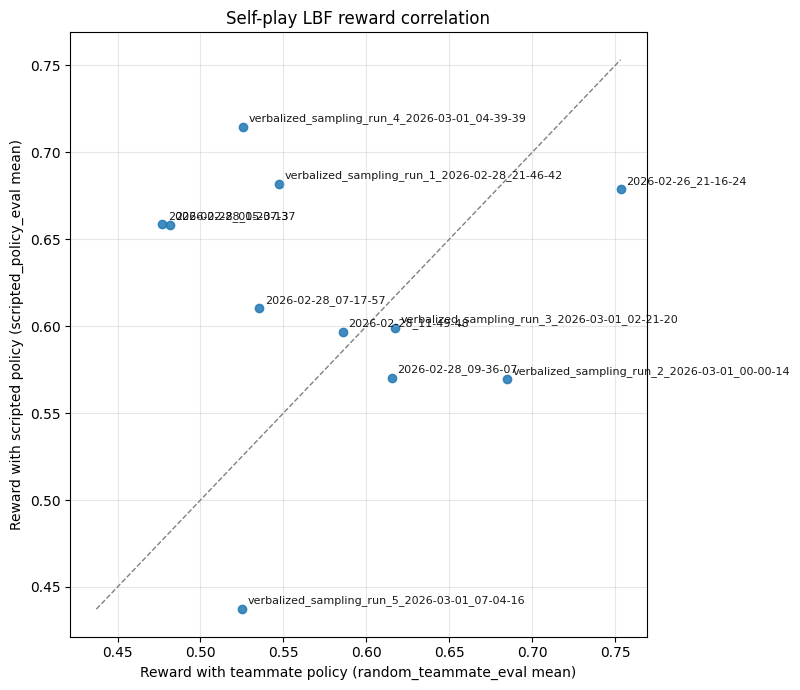

Pearson r:  -0.0362
Spearman ρ: -0.1909


In [7]:
import matplotlib.pyplot as plt

if self_play_eval_df.empty:
    print('No self-play LBF runs found with both scripted/random eval files.')
else:
    pearson_r = self_play_eval_df['random_teammate_reward_mean'].corr(
        self_play_eval_df['scripted_reward_mean'], method='pearson'
    )
    spearman_rho = self_play_eval_df['random_teammate_reward_mean'].corr(
        self_play_eval_df['scripted_reward_mean'], method='spearman'
    )

    plt.figure(figsize=(8, 7))
    plt.scatter(
        self_play_eval_df['random_teammate_reward_mean'],
        self_play_eval_df['scripted_reward_mean'],
        alpha=0.85,
    )

    for _, row in self_play_eval_df.iterrows():
        plt.annotate(
            row['run_tag'],
            (row['random_teammate_reward_mean'], row['scripted_reward_mean']),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=8,
            alpha=0.9,
        )

    lo = min(
        self_play_eval_df['random_teammate_reward_mean'].min(),
        self_play_eval_df['scripted_reward_mean'].min(),
    )
    hi = max(
        self_play_eval_df['random_teammate_reward_mean'].max(),
        self_play_eval_df['scripted_reward_mean'].max(),
    )
    plt.plot([lo, hi], [lo, hi], linestyle='--', color='gray', linewidth=1)

    plt.xlabel('Reward with teammate policy (random_teammate_eval mean)')
    plt.ylabel('Reward with scripted policy (scripted_policy_eval mean)')
    plt.title('Self-play LBF reward correlation')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f'Pearson r:  {pearson_r:.4f}')
    print(f'Spearman ρ: {spearman_rho:.4f}')
